In [18]:
import matplotlib as mpl
import pylab as plt
import numpy as np
import time
import pickle
from scipy.interpolate import RegularGridInterpolator, interp1d
from scipy.integrate import odeint
%matplotlib inline


In [19]:


rho=10
X0=20
Y0=4
#Y0=0
v0=5
place=9
def PotentialWig(X,Y,rho,X0,Y0):
    phase=2*np.pi*Y/Y0
    logic=(phase>(place*np.pi)) * (phase<((place+1)*np.pi))
    V=rho*pow(X-logic*X0*np.sin(2*np.pi*Y/Y0),2)
    return V

def PotentialPul(X,Y,rho,X0,Y0):
    phase=2*np.pi*Y/Y0
    logic=(phase>(place*np.pi)) * (phase<((place+1)*np.pi))
    V=rho*(1-X0*logic*np.sin(phase))*pow(X,2)
    return V


def PotentialWig2(X,Y,rho,X0,Y0):
    phase=2*np.pi*Y/Y0
    logic=(phase>(place*np.pi)) * (phase<((place+1)*np.pi))
    V=rho*pow(X-logic*X0*np.sin(2*np.pi*Y/Y0),2)**2
    return V

def PotentialPul2(X,Y,rho,X0,Y0):
    phase=2*np.pi*Y/Y0
    logic=(phase>(place*np.pi)) * (phase<((place+1)*np.pi))
    V=rho*(1-X0*logic*np.sin(phase))*pow(X,2)
    return V

def GradVWig(X,Y,rho,X0,Y0):
    phase=2*np.pi*Y/Y0
    logic=(phase>(place*np.pi)) * (phase<((place+1)*np.pi))
    f=(X-X0*logic*np.sin(2*np.pi*Y/Y0))
    
    dVdx=2*rho*f
    dVdy=-4*np.pi*rho*X0*logic/Y0*np.cos(2*np.pi*Y/Y0)*f
    return np.array([dVdx,dVdy])

def GradVPul(X,Y,rho,X0,Y0):
    phase=2*np.pi*Y/Y0
    logic=(phase>(place*np.pi)) * (phase<((place+1)*np.pi))
    dVdx=2*rho*(1-X0*logic*np.sin(2*np.pi*Y/Y0))*X
    dVdy=2*np.pi*rho*X0*logic/Y0*np.cos(2*np.pi*Y/Y0)*X**2
    return np.array([dVdx,dVdy])



def SampleInitConditions(v0,rho,N=100):
    x=np.random.normal(0,np.sqrt(1/(2.*rho)),N)
    y=np.zeros_like(x)
    vx=np.random.normal(0,1,N)
    vy=np.random.normal(v0,1,N)
    return np.array([x,y,vx,vy]).T


def SampleInitConditionsPotential(v0,Potential,N=100,xlim=5):
    vars=np.linspace(-xlim,xlim,N)
    xpot=np.exp(-Potential(vars,0))
    tosample=interp1d(np.cumsum(xpot)/sum(xpot),vars)
    x=tosample(np.random.random(N))
    y=np.zeros_like(x)
    vx=np.random.normal(0,1,N)
    vy=np.random.normal(v0,1,N)
    return np.array([x,y,vx,vy]).T




In [20]:

C0=10
C1=10
B1=1


za0=25
periods=1
a=7

def PotentialPul2(X,Y,rho,X0,Y0):
    logic=(((Y-za0)<(a/2))*((Y-za0)>(-a/2)))
    V=(C0+C1*logic*np.cos(np.pi*periods*(Y-za0)/a)**2)*pow(X,2)
    return V


def PotentialWig2(X,Y,rho,X0,Y0):
    logic=(((Y-za0)<a/2)*((Y-za0)>(-a/2)))
    V=C0*pow(X-logic*B1*np.cos(np.pi*periods*(Y-za0)/a)**2,2)
    return V



def GradVPul2(X,Y,rho,X0,Y0):
    logic=(((Y-za0)<a/2)*((Y-za0)>(-a/2)))

    dVdx=2*(C0+C1*np.cos(np.pi*periods*(Y-za0)/a)**2*logic)*X
    dVdy=-np.pi*periods/a*C1*np.sin(2*np.pi*periods*(Y-za0)/a)*logic
    return np.array([dVdx,dVdy])


def GradVWig2(X,Y,rho,X0,Y0):
    logic=(((Y-za0)<a/2)*((Y-za0)>(-a/2)))
    
    dVdx=2*C0*(X-B1*np.cos(np.pi*periods*(Y-za0)/a)**2*logic)
    dVdy=2*np.pi*periods/a*C0 *B1*np.sin(2*np.pi*periods*(Y-za0)/a)*(X-B1*np.cos(np.pi*periods*(Y-za0)/a)**2)*logic
    return np.array([dVdx,dVdy])

In [21]:
Potential=lambda X,Y : PotentialWig2(X,Y,rho,X0,Y0)
GradV=lambda X,Y     : GradVWig2(X,Y,rho,X0,Y0)

In [22]:
XExtent=5
YExtent=20
XX,YY=np.meshgrid(np.linspace(-XExtent,XExtent,1000),np.linspace(0,YExtent,1000))

#rho=10
#X0=2
#Y0=10




In [23]:
def dpdx(X,t):
    force=-GradV(X[0],X[1])
    return [X[2],X[3],force[0],force[1]]


In [24]:
def CollectThermoQuantities(Sols, XArrowPos,YArrowPos,width=0.2):
    ReturnVec=[]
    for i in range(0,len(XArrowPos)):
        ReturnVecRow=[]
        for j in range(0,len(XArrowPos[0])):

            PosX=XArrowPos[i,j]
            PosY=YArrowPos[i,j]
            denom=2*width**2

            distances=(Sols[:,:,0]-PosX)**2+(Sols[:,:,1]-PosY)**2
            select=distances<(8**2*denom)
            #print("Time for selecting: " + str(time.time()-Time0))

            if(sum(sum(select))>0):
                #Weights=np.ones_like(distances[select])
                Weights=np.exp(-distances[select]/denom)
                #print("Time for weights: " + str(time.time()-Time0))

                SumWs=sum(Weights)
                SelSolutions=Sols[select]
                SelX=SelSolutions[:,2]
                SelY=SelSolutions[:,3]
                #print("Time for sumw2: " + str(time.time()-Time0))

                Avevx=sum(SelX*Weights)/SumWs
                Avevy=sum(SelY*Weights)/SumWs
                Avevx2=sum((SelX)**2*Weights)/SumWs
                Avevy2=sum((SelY)**2*Weights)/SumWs
                ReturnVecRow.append([Avevx,Avevy,Avevx2,Avevy2,SumWs])
                #print("Time for products: " + str(time.time()-Time0))

            else:
                ReturnVecRow.append([0,0,0,0,0])
            #print("Time for adding: " + str(time.time()-Time0))
        print(i)    
        ReturnVec.append(ReturnVecRow)
    return np.array(ReturnVec)
    

def GetSolutions(dpdx,Initials,ts,N=-1):
    AllSolutions=[]
    if N==-1:
        N=len(Initials)
    for i in range(N):
        sol=odeint(dpdx,Initials[i],t=ts)
        AllSolutions.append(sol)
    return np.array(AllSolutions)

In [25]:
def RandomCollision(MBcx,MBcy,MBT, vx,vy):
    random_vx=np.random.normal(loc=MBcx, scale=MBT)
    random_vy=np.random.normal(loc=MBcy, scale=MBT)
    qvec=(vx-random_vx,vy-random_vy)
    q=np.linalg.norm(qvec)
    pvec=((vx+random_vx)/2.,(vy+random_vy)/2.)
    newth=np.random.random()*2.*np.pi
    newvec=(pvec[0]+q*np.cos(newth)/2.,pvec[1]+q*np.sin(newth)/2.)
    return newvec

In [26]:

def GetInterpolators(ThermQuantities):
    T_interp=RegularGridInterpolator((np.unique(XArrowPos.flatten()),np.unique(YArrowPos.flatten())),np.sqrt(StreamArrowDirs[:,:,2]+StreamArrowDirs[:,:,3]).T/np.sqrt(2),bounds_error=False,fill_value=0)
    px_interp=RegularGridInterpolator((np.unique(XArrowPos.flatten()),np.unique(YArrowPos.flatten())),StreamArrowDirs[:,:,0].T,bounds_error=False,fill_value=0)
    py_interp=RegularGridInterpolator((np.unique(XArrowPos.flatten()),np.unique(YArrowPos.flatten())),StreamArrowDirs[:,:,1].T,bounds_error=False,fill_value=0)
    rho_interp=RegularGridInterpolator((np.unique(XArrowPos.flatten()),np.unique(YArrowPos.flatten())),StreamArrowDirs[:,:,4].T,bounds_error=False,fill_value=0)
    InterpDict={'rho':rho_interp,'T':T_interp,'px':px_interp,'py':py_interp}
    return InterpDict

In [27]:
def MakeSecondaries(Solutions,Interpolators,NSec=10,scaledxs=5e-6):

    NSec=10
    Secondaries=[]

    for sol in Solutions:

        rho_alongpath=Interpolators['rho'](sol[:,0:2])
        T_alongpath=Interpolators['T'](sol[:,0:2])
        px_alongpath=Interpolators['px'](sol[:,0:2])
        py_alongpath=Interpolators['py'](sol[:,0:2])
        relV=((px_alongpath-sol[:,2])**2+(py_alongpath-sol[:,3])**2)**0.5

        ExpectedInteractions=np.cumsum(relV*rho_alongpath*scaledxs)
        ProbOfSurvival=np.exp(-ExpectedInteractions)

        randomfun=interp1d(ProbOfSurvival,range(0,len(ProbOfSurvival)),fill_value=0,bounds_error=False)
        RandPos=np.random.random(size=NSec)
        SecondaryPoints=randomfun(RandPos).astype('int')

        for i in SecondaryPoints:
            x=sol[i,0]
            y=sol[i,1]
            Temp=Interpolators['T']((x,y))
            px=Interpolators['px']((x,y))
            py=Interpolators['py']((x,y))
            SecMom=RandomCollision(px,py,Temp,sol[i,2],sol[i,3])
            Secondaries.append([x,y,SecMom[0],SecMom[1]])

    return(Secondaries)

In [28]:
v0=5
MaxT=40
tPoints=1000

XExtent=5
YExtent=50
YDivs=200
XDivs=60
XArrowPos,YArrowPos=np.meshgrid(np.linspace(-XExtent,XExtent,XDivs),np.linspace(0,YExtent,YDivs))
ts=np.linspace(0,MaxT,tPoints)

N=1000
#for Y0 in [2,30,14,4,24,6,20,8,10,18,12,16,22]:
for Y0 in [Y0]:
    print(Y0)

    Inits=SampleInitConditionsPotential(v0,Potential,N)
    
    AllSolutions=GetSolutions(dpdx,Inits,ts)
    
    StreamArrowDirs=CollectThermoQuantities(AllSolutions,XArrowPos,YArrowPos,0.2)
    
    f=open("file_"+str(Y0)+".dat",'wb')
    pickle.dump(StreamArrowDirs,f)
    f.close()



4
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199


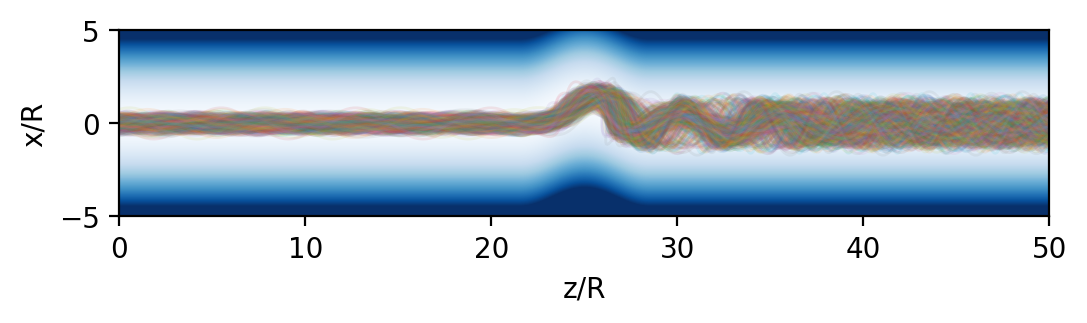

In [29]:


XX,YY=np.meshgrid(np.linspace(-XExtent,XExtent,1000),np.linspace(0,YExtent,1000))

plt.figure(figsize=(6,5),dpi=200)
plt.imshow(Potential(XX,YY).T,extent=(0,YExtent,-XExtent,XExtent),origin='lower',cmap='Blues',zorder=0,aspect=1)
plt.clim(0,200)
#plt.colorbar()

#plt.title("V")

plt.xlim(0,50)
plt.ylim(-5,5)
for sol in AllSolutions[0:1000]:
    plt.plot(sol[:,1],sol[:,0],linewidth=1,zorder=1,alpha=0.1)
    #plt.plot([sol[-1,1]],[sol[-1,0]],'o',color='red')
plt.ylabel("x/R")
plt.xlabel("z/R")
#plt.xticks([])
plt.show()



<>:4: SyntaxWarning: invalid escape sequence '\p'
<>:4: SyntaxWarning: invalid escape sequence '\p'
/var/folders/vy/ll7qjbxx66v846pybl4qyvh80000gs/T/ipykernel_62417/4058209680.py:4: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(np.linspace(0,YExtent,YDivs-1),np.sqrt(sum((StreamArrowDirs[:,:,2]*StreamArrowDirs[:,:,4]).T)[1:]/sum((StreamArrowDirs[:,:,4]).T)[1:]),label='RMS(p) [$\propto \sqrt{T}$] ' ,color='green')


(-4.0, 8.0)

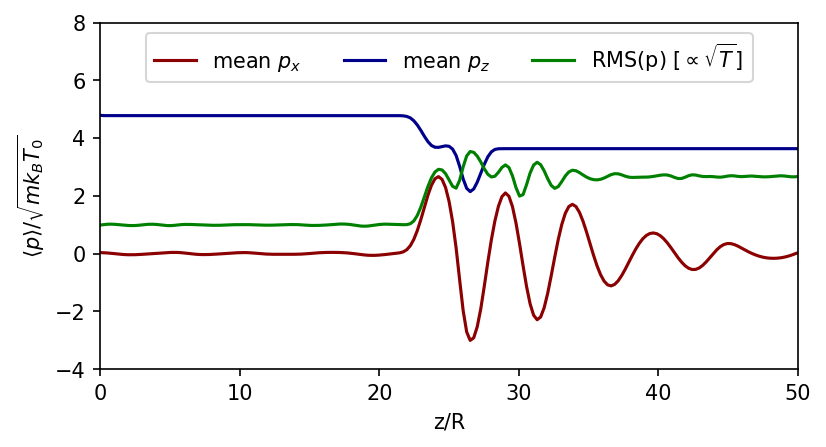

In [30]:
plt.figure(figsize=(6,3),dpi=150)
plt.plot(np.linspace(0,YExtent,YDivs-1),sum((StreamArrowDirs[:,:,0]*StreamArrowDirs[:,:,4]).T)[1:]/sum((StreamArrowDirs[:,:,4]).T)[1:],label='mean $p_x$',color='DarkRed')
plt.plot(np.linspace(0,YExtent,YDivs-1),sum((StreamArrowDirs[:,:,1]*StreamArrowDirs[:,:,4]).T)[1:]/sum((StreamArrowDirs[:,:,4]).T)[1:],label='mean $p_z$',color='DarkBlue')
plt.plot(np.linspace(0,YExtent,YDivs-1),np.sqrt(sum((StreamArrowDirs[:,:,2]*StreamArrowDirs[:,:,4]).T)[1:]/sum((StreamArrowDirs[:,:,4]).T)[1:]),label='RMS(p) [$\propto \sqrt{T}$] ' ,color='green')

plt.xlim(0,50)

plt.xlabel("z/R")
plt.ylabel(r"$\langle p \rangle / \sqrt{m k_B T_0}$ ")
plt.legend(loc='upper center',ncol=3)
plt.ylim(-4,8)

<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:9: SyntaxWarning: invalid escape sequence '\D'
/var/folders/vy/ll7qjbxx66v846pybl4qyvh80000gs/T/ipykernel_62417/1036170126.py:9: SyntaxWarning: invalid escape sequence '\D'
  plt.xlabel("$\Delta p_z/p_0$")


Text(0.5, 0, '$\\Delta p_z/p_0$')

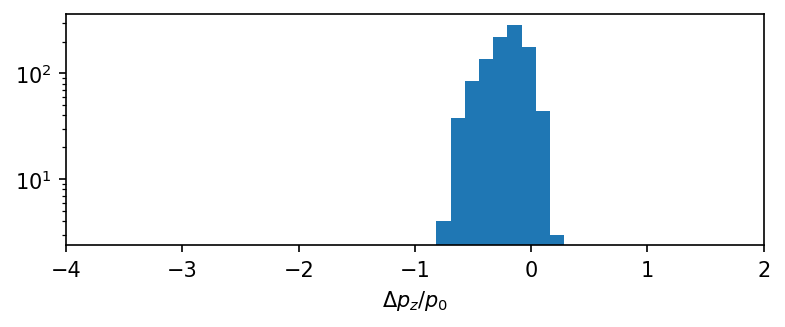

In [31]:
plt.figure(figsize=(6,2),dpi=150)
diffs=[]
for sol in AllSolutions:
    diffs.append((sol[-1,3]-sol[0,3])/sol[0,3])
plt.hist(diffs,bins=np.linspace(-4,2,50))
#plt.plot([-5,-5],[0,90],color='red')
plt.semilogy()
plt.xlim(-4,2)
plt.xlabel("$\Delta p_z/p_0$")

In [32]:
CollectThermoQuantities(AllSolutions,np.array([[0]]),np.array([[40]]),1)[0,0]

0


array([4.44949255e-01, 3.66161776e+00, 7.34410211e+00, 1.38135836e+01,
       1.47188061e+04])

In [33]:
def GetFOMs(solns):
    NoRefl=0
    for sol in solns:
        if((sol[-1,3]-sol[0,3])/sol[0,3]<-1):
            NoRefl=NoRefl+1
    FracRefl=NoRefl/len(solns)
    vx1,vy1,vxs1,vys1,N1=CollectThermoQuantities(AllSolutions,np.array([[0]]),np.array([[2]]),1)[0,0]
    vx2,vy2,vxs2,vys2,N2=CollectThermoQuantities(AllSolutions,np.array([[0]]),np.array([[40]]),1)[0,0]

    T1=(vxs1-vx1**2+vys1-vy1**2)
    T2=(vxs2-vx2**2+vys2-vy2**2)
    M1= (vx1**2+vy1**2)/(vxs1+vys1-vx1**2-vy1**2)
    M2= (vx2**2+vy2**2)/(vxs2+vys2-vx2**2-vy2**2)
    return [FracRefl,vx1,vx2,vy1,vy2,T1,T2,M1,M2,N2-N1]

In [34]:
v0=5
MaxT=30
tPoints=1000

XExtent=5
YExtent=50
YDivs=200
XDivs=60
XArrowPos,YArrowPos=np.meshgrid(np.linspace(-XExtent,XExtent,XDivs),np.linspace(0,YExtent,YDivs))
ts=np.linspace(0,MaxT,tPoints)
AllFOMs=[]
N=1000
#for Y0 in [2,30,14,4,24,6,20,8,10,18,12,16,22]:
B1s=[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.25,1.5,1.75,2.0,2.5,3.0]
As=range(1,14,1)
#B1s=[0.1,0.4,0.8,1.0,1.5,2.0,3.0]
#As=range(1,10,1)

#for B1 in B1s:

for a in As:
    FOMs=[]
    for B1 in B1s:
        print(a,B1)
        Inits=SampleInitConditionsPotential(v0,Potential,N)
    
        AllSolutions=GetSolutions(dpdx,Inits,ts)
    
        FOMs.append(GetFOMs(AllSolutions))
    AllFOMs.append(np.array(FOMs))
AllFOMs=np.array(AllFOMs)

1 0.1
0
0
1 0.2
0
0
1 0.3
0
0
1 0.4
0
0
1 0.5
0
0
1 0.6
0
0
1 0.7
0
0
1 0.8
0
0
1 0.9
0
0
1 1.0
0
0
1 1.25
0
0
1 1.5
0
0
1 1.75
0
0
1 2.0
0
0
1 2.5
0
0
1 3.0
0
0
2 0.1


/var/folders/vy/ll7qjbxx66v846pybl4qyvh80000gs/T/ipykernel_62417/956319427.py:13: RuntimeWarning: invalid value encountered in scalar divide
  M2= (vx2**2+vy2**2)/(vxs2+vys2-vx2**2-vy2**2)


0
0
2 0.2
0
0
2 0.3
0
0
2 0.4
0
0
2 0.5
0
0
2 0.6
0
0
2 0.7
0
0
2 0.8
0
0
2 0.9
0
0
2 1.0
0
0
2 1.25
0
0
2 1.5
0
0
2 1.75
0
0
2 2.0
0
0
2 2.5
0
0
2 3.0
0
0
3 0.1
0
0
3 0.2
0
0
3 0.3
0
0
3 0.4
0
0
3 0.5
0
0
3 0.6
0
0
3 0.7
0
0
3 0.8
0
0
3 0.9
0
0
3 1.0
0
0
3 1.25
0
0
3 1.5
0
0
3 1.75
0
0
3 2.0
0
0
3 2.5
0
0
3 3.0
0
0
4 0.1
0
0
4 0.2
0
0
4 0.3
0
0
4 0.4
0
0
4 0.5
0
0
4 0.6
0
0
4 0.7
0
0
4 0.8
0
0
4 0.9
0
0
4 1.0
0
0
4 1.25
0
0
4 1.5
0
0
4 1.75
0
0
4 2.0
0
0
4 2.5
0
0
4 3.0
0
0
5 0.1
0
0
5 0.2
0
0
5 0.3
0
0
5 0.4
0
0
5 0.5
0
0
5 0.6
0
0
5 0.7
0
0
5 0.8
0
0
5 0.9
0
0
5 1.0
0
0
5 1.25
0
0
5 1.5
0
0
5 1.75
0
0
5 2.0
0
0
5 2.5
0
0
5 3.0
0
0
6 0.1
0
0
6 0.2
0
0
6 0.3
0
0
6 0.4
0
0
6 0.5
0
0
6 0.6
0
0
6 0.7
0
0
6 0.8
0
0
6 0.9
0
0
6 1.0
0
0
6 1.25
0
0
6 1.5
0
0
6 1.75
0
0
6 2.0
0
0
6 2.5
0
0
6 3.0
0
0
7 0.1
0
0
7 0.2
0
0
7 0.3
0
0
7 0.4
0
0
7 0.5
0
0
7 0.6
0
0
7 0.7
0
0
7 0.8
0
0
7 0.9
0
0
7 1.0
0
0
7 1.25
0
0
7 1.5
0
0
7 1.75
0
0
7 2.0
0
0
7 2.5
0
0
7 3.0
0
0
8 0.1
0
0
8 0.2
0
0
8 0.3
0
0
8 0.

v0=3
MaxT=30
tPoints=1000

XExtent=5
YExtent=50
YDivs=200
XDivs=60
XArrowPos,YArrowPos=np.meshgrid(np.linspace(-XExtent,XExtent,XDivs),np.linspace(0,YExtent,YDivs))
ts=np.linspace(0,MaxT,tPoints)
AllFOMs2=[]
N=1000
#for Y0 in [2,30,14,4,24,6,20,8,10,18,12,16,22]:
B1s=[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.25,1.5,1.75,2.0,2.5,3.0]
As=range(1,14,1)

#for B1 in B1s:

for a in As:
    FOMs=[]
    for B1 in B1s:
        print(a,B1)
        Inits=SampleInitConditionsPotential(v0,Potential,N)
    
        AllSolutions=GetSolutions(dpdx,Inits,ts)
    
        FOMs.append(GetFOMs(AllSolutions))
    AllFOMs2.append(np.array(FOMs))
AllFOMs2=np.array(AllFOMs2)

In [36]:
AllFOMs=np.array(AllFOMs)

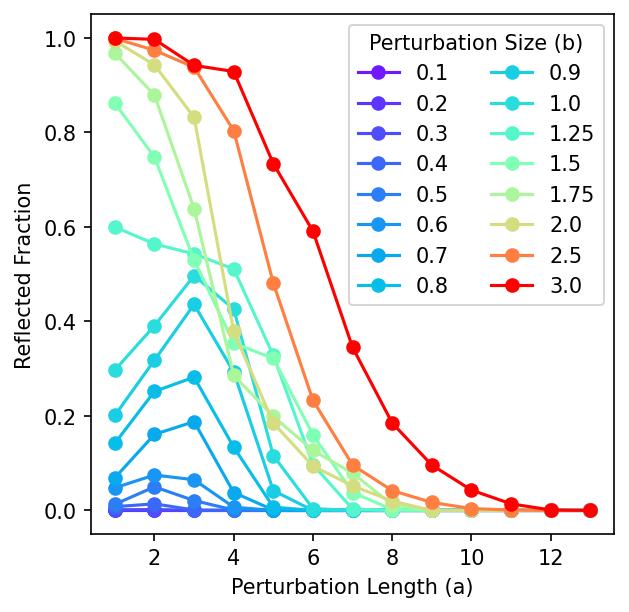

In [37]:
plt.figure(figsize=(4.5,4.5),dpi=150)
cmap=plt.colormaps.get('rainbow')
for bi in range(0,len(B1s)):
    plt.plot(As,AllFOMs[:,bi,0],'o-',label=B1s[bi],color=cmap(B1s[bi]/3)) 
plt.ylabel("Reflected Fraction")
plt.xlabel("Perturbation Length (a)")
plt.legend(loc='upper right',ncol=2,title='Perturbation Size (b)')
#plt.xlim(0,2.5)
#plt.ylim(-0.02,0.15)
plt.show()

In [38]:
AllFOMs[:,bi,0]

array([1.   , 0.997, 0.942, 0.929, 0.734, 0.591, 0.345, 0.185, 0.096,
       0.043, 0.014, 0.001, 0.   ])

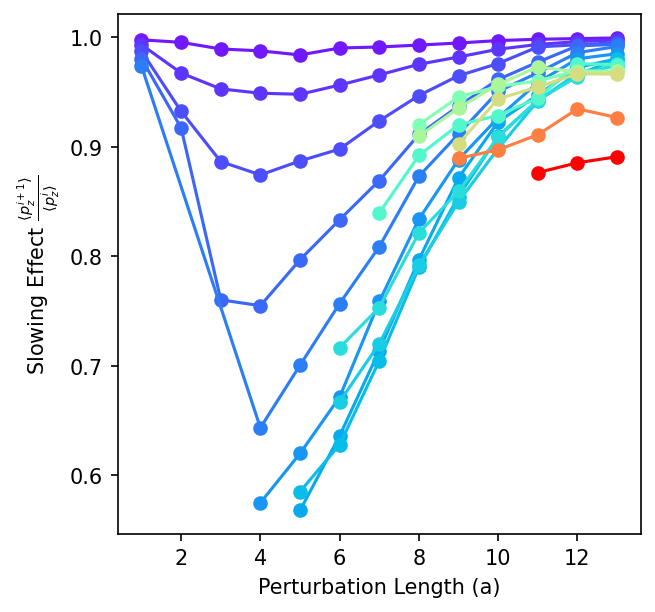

In [39]:
plt.figure(figsize=(4.5,4.5),dpi=150)
As=np.array(As)
cmap=plt.colormaps.get('rainbow')
for bi in range(0,len(B1s)):
    sel=AllFOMs[:,bi,0]<0.02
    plt.plot(As[sel],AllFOMs[sel,bi,4]/AllFOMs[sel,bi,3],'o-',label=B1s[bi],color=cmap(B1s[bi]/3)) 
plt.ylabel(r"Slowing Effect $\frac{\langle p_z^{i+1} \rangle}{\langle p_z^{i} \rangle}$")

plt.xlabel("Perturbation Length (a)")
#plt.legend(loc='lower right',ncol=2,title='Perturbation Size (B1)')
#plt.xlim(0,2.5)
#plt.ylim(-0.02,0.15)
plt.show()

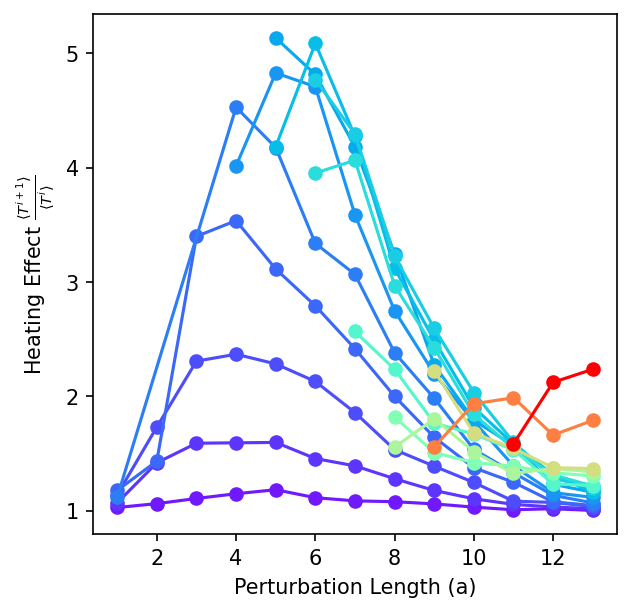

In [40]:
plt.figure(figsize=(4.5,4.5),dpi=150)
As=np.array(As)
cmap=plt.colormaps.get('rainbow')
for bi in range(0,len(B1s)):
    sel=AllFOMs[:,bi,0]<0.02
    plt.plot(As[sel],AllFOMs[sel,bi,6]/AllFOMs[sel,bi,5],'o-',label=B1s[bi],color=cmap(B1s[bi]/3)) 
plt.ylabel(r"Heating Effect $\frac{\langle T^{i+1} \rangle}{\langle T^{i} \rangle}$")

plt.xlabel("Perturbation Length (a)")
#plt.legend(loc='lower right',ncol=2,title='Perturbation Size (B1)')
#plt.xlim(0,2.5)
#plt.ylim(-0.02,0.15)
plt.show()

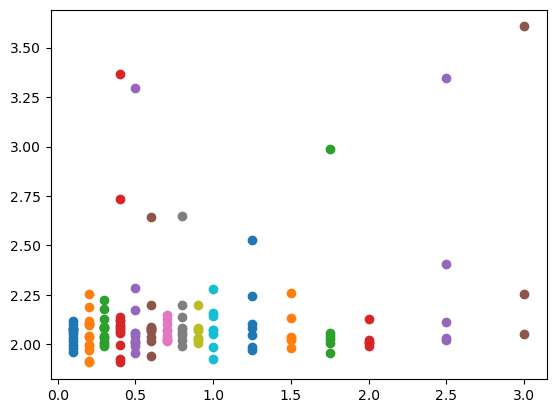

In [41]:
for bi in range(0,len(B1s)):
    sel=AllFOMs[:,bi,0]<0.02
    plt.plot(np.ones_like(AllFOMs[sel,bi,5])*B1s[bi],AllFOMs[sel,bi,5],'o')

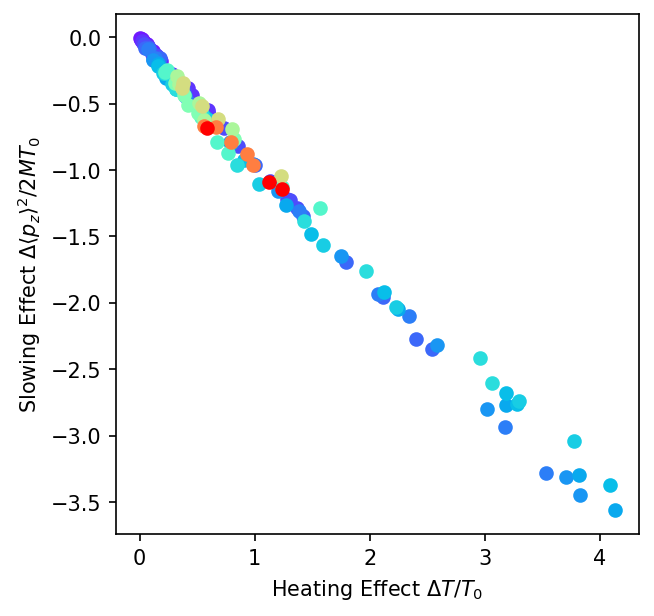

In [48]:
plt.figure(figsize=(4.5,4.5),dpi=150)
As=np.array(As)
cmap=plt.colormaps.get('rainbow')
#plt.plot([0,4],[0,-4],'--',color='dimgrey')
for bi in range(0,len(B1s)):
    sel=AllFOMs[:,bi,0]<0.02
    
    plt.plot((AllFOMs[sel,bi,6]-AllFOMs[sel,bi,5])/AllFOMs[sel,bi,5],(AllFOMs[sel,bi,4]**2-AllFOMs[sel,bi,3]**2)/(2*AllFOMs[sel,bi,5]),'o',label=B1s[bi],color=cmap(B1s[bi]/3)) 
    
plt.xlabel(r"Heating Effect $\Delta T / T_0 $ ")
plt.ylabel(r"Slowing Effect $\Delta \langle p_z\rangle^2 / 2 M T_0 $")

plt.show()